In [1]:
# ============================================================
# HASIL PENELITIAN PROPHET UNTUK SKRIPSI
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")

# ============================================================
# LOKASI FILE
# ============================================================

BASE_DIR = os.getcwd()

FILE_EXCEL = os.path.join(
    BASE_DIR, "dataset/data_clean_ok.xlsx"
)

OUTPUT_FOLDER = os.path.join(
    BASE_DIR, "hasil_penelitian"
)

os.makedirs(
    OUTPUT_FOLDER,
    exist_ok=True
)

# ============================================================
# PILIH PRODUK
# ============================================================
SHEET = "aqua_600ml"  # pilih sheet sesuai produk yang diinginkan
CHANGEPOINT = {
    "surya_kaleng":0.1,
    "sampoerna_16":0.05,
    "aqua_600ml":0.01,
    "aqua_1500ml":0.01,
    "indomie":0.01,
    "golda": 0.1,
    "teh_botol_450ml": 0.01,
    "surya_16": 0.1
}

CURRENT_SCALE = CHANGEPOINT[SHEET]
LEAD_TIME = 14

print("="*60)
print("HASIL PENELITIAN PROPHET")
print("="*60)
print("Dataset :", FILE_EXCEL)
print("Produk  :", SHEET)
print("="*60)

Importing plotly failed. Interactive plots will not work.


HASIL PENELITIAN PROPHET
Dataset : d:\SKRIPSI\POS\PROPHET\dataset/data_clean_ok.xlsx
Produk  : aqua_600ml


In [2]:
# ============================================================
# MEMBACA DATASET
# ============================================================

df = pd.read_excel(
    FILE_EXCEL, sheet_name=SHEET
)

df["ds"] = pd.to_datetime(df["ds"])
df = df.sort_values("ds")
df = df.dropna()

# hari toko tutup
df.loc[df["y"] == 0, "y"] = np.nan
print(df.head())
print()
print(df.info())
print()
print(df.describe())

          ds     y
0 2023-01-01  35.0
1 2023-01-02  13.0
2 2023-01-03   8.0
3 2023-01-04   8.0
4 2023-01-05  13.0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ds      1092 non-null   datetime64[ns]
 1   y       1087 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 17.2 KB
None

                                  ds            y
count                           1092  1087.000000
mean   2024-07-02 00:39:33.626373632    16.755290
min              2023-01-01 00:00:00     1.000000
25%              2023-09-30 18:00:00    11.000000
50%              2024-07-03 12:00:00    14.000000
75%              2025-04-02 06:00:00    20.000000
max              2025-12-31 00:00:00    67.000000
std                              NaN     9.446218


In [3]:
# ============================================================
# RINGKASAN DATASET
# ============================================================

print("="*60)
print("RINGKASAN DATASET")
print("="*60)
print("Tanggal Awal :", df["ds"].min().date())
print("Tanggal Akhir :", df["ds"].max().date())
print("Jumlah Data :", len(df))
print("Missing Value :", df["y"].isna().sum())
print("Lead Time :", LEAD_TIME)
print("="*60)

RINGKASAN DATASET
Tanggal Awal : 2023-01-01
Tanggal Akhir : 2025-12-31
Jumlah Data : 1092
Missing Value : 5
Lead Time : 14


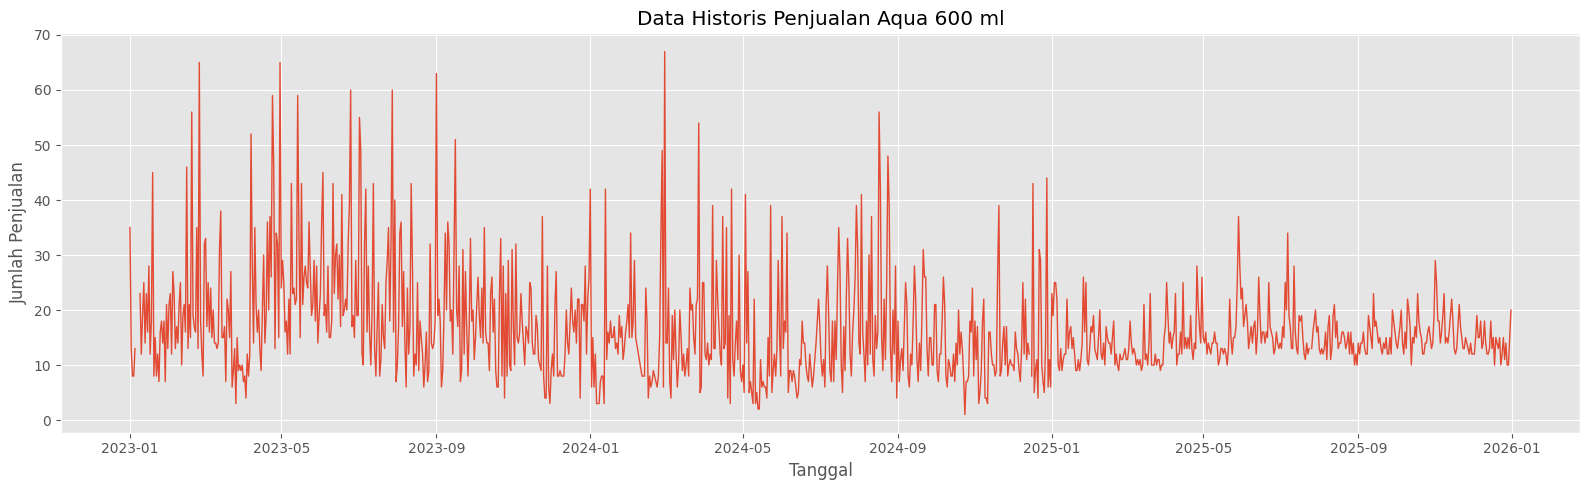

In [4]:
# ============================================================
# GRAFIK HISTORIS
# ============================================================

plt.figure(figsize=(16,5))

plt.plot( df["ds"], df["y"], linewidth=1)
plt.title("Data Historis Penjualan Aqua 600 ml")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "01_data_historis.png"
    ),
    dpi=300
)

plt.show()

In [5]:
# ============================================
# PERIODE EVALUASI
# ============================================

TRAIN_END = "2025-12-17"

LEAD_TIME = 14

train = df[df["ds"] <= TRAIN_END].copy()

test = df[
    (df["ds"] > TRAIN_END)
].head(LEAD_TIME).copy()
# ============================================================
# TRAIN TEST SPLIT
# ============================================================

# train = df.iloc[:-LEAD_TIME].copy()
# test = df.iloc[-LEAD_TIME:].copy()

print()
print("Training :",len(train))
print("Testing :",len(test))
print()

display(train.tail())
display(test)


Training : 1078
Testing : 14



,ds,y
1073,2025-12-13,12.0
1074,2025-12-14,13.0
1075,2025-12-15,18.0
1076,2025-12-16,13.0
1077,2025-12-17,15.0


,ds,y
1078,2025-12-18,10.0
1079,2025-12-19,15.0
1080,2025-12-20,14.0
1081,2025-12-21,13.0
1082,2025-12-22,15.0
1083,2025-12-23,10.0
1084,2025-12-24,12.0
1085,2025-12-25,15.0
1086,2025-12-26,11.0
1087,2025-12-27,14.0


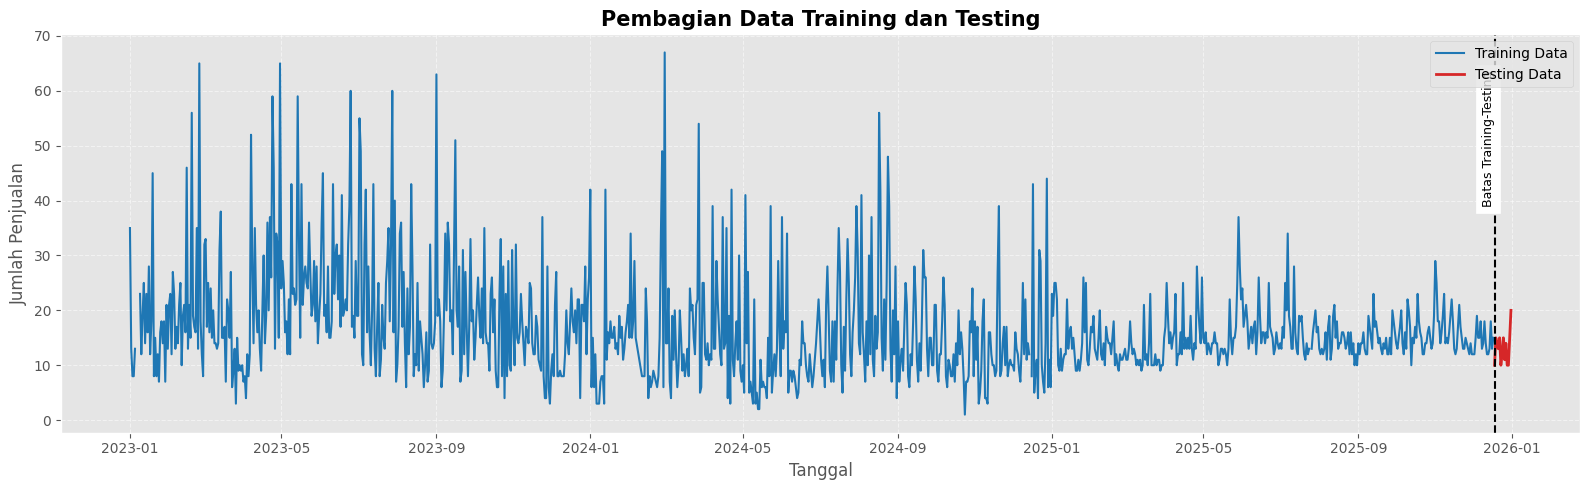

In [6]:
# ============================================================
# VISUALISASI PEMBAGIAN DATA TRAINING DAN TESTING
# ============================================================

plt.figure(figsize=(16,5))

# Training
plt.plot(
    train["ds"],
    train["y"],
    color="tab:blue",
    linewidth=1.5,
    label="Training Data"
)

# Testing
plt.plot(
    test["ds"],
    test["y"],
    color="tab:red",
    linewidth=2,
    label="Testing Data"
)

# Garis batas Training - Testing
plt.axvline(
    x=test["ds"].iloc[0],
    color="black",
    linestyle="--",
    linewidth=1.5
)

# Tulisan batas
plt.text(
    test["ds"].iloc[0],
    max(df["y"]) * 0.95,
    "Batas Training-Testing",
    rotation=90,
    fontsize=9,
    va="top",
    ha="right",
    backgroundcolor="white"
)

plt.title(
    "Pembagian Data Training dan Testing",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan")

plt.legend(loc="upper right")

plt.grid(
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "02_training_testing.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

OSError: [Errno 22] Invalid argument: 'd:\\SKRIPSI\\POS\\PROPHET\\hasil_penelitian\\03_training_testing_zoom.png'

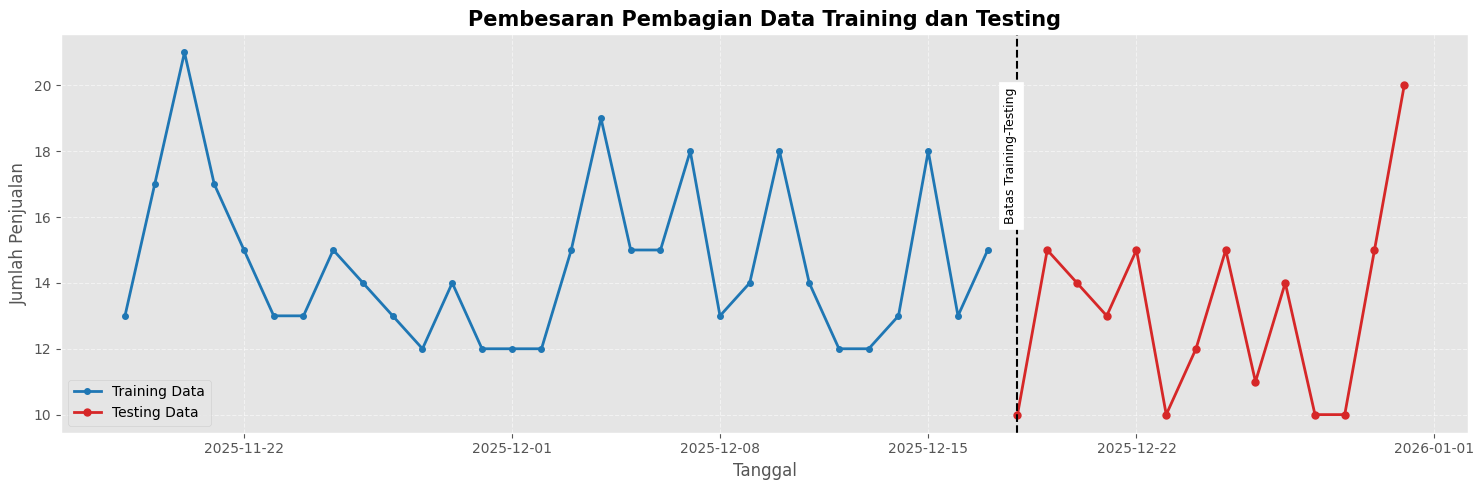

In [7]:
# ============================================================
# VISUALISASI ZOOM TRAINING DAN TESTING
# ============================================================

import pandas as pd

# Ambil 30 hari terakhir training
train_zoom = train.tail(30)

# Gabungkan dengan seluruh testing
zoom_df = pd.concat([train_zoom, test])

plt.figure(figsize=(15,5))

# Training
plt.plot(
    train_zoom["ds"],
    train_zoom["y"],
    color="tab:blue",
    linewidth=2,
    marker="o",
    markersize=4,
    label="Training Data"
)

# Testing
plt.plot(
    test["ds"],
    test["y"],
    color="tab:red",
    linewidth=2,
    marker="o",
    markersize=5,
    label="Testing Data"
)

# Garis batas
plt.axvline(
    x=test["ds"].iloc[0],
    color="black",
    linestyle="--",
    linewidth=1.5
)

# Tulisan batas
plt.text(
    test["ds"].iloc[0],
    max(zoom_df["y"])*0.95,
    "Batas Training-Testing",
    rotation=90,
    fontsize=9,
    ha="right",
    va="top",
    backgroundcolor="white"
)

plt.title(
    "Pembesaran Pembagian Data Training dan Testing",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Tanggal")

plt.ylabel("Jumlah Penjualan")

plt.grid(
    linestyle="--",
    alpha=0.5
)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "03_training_testing_zoom.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# MEMBANGUN MODEL PROPHET
# ============================================================

model_eval = Prophet(
    changepoint_prior_scale=CURRENT_SCALE,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model_eval.fit(train)

10:26:49 - cmdstanpy - INFO - Chain [1] start processing
10:26:49 - cmdstanpy - INFO - Chain [1] done processing


In [ ]:
# ============================================================
# PREDIKSI DATA TESTING
# ============================================================

future = test[["ds"]]

forecast = model.predict(future)

forecast[
    [
        "ds",
        "yhat",
        "yhat_lower",
        "yhat_upper"
    ]

]

,ds,yhat,yhat_lower,yhat_upper
0,2025-05-27,12.036447,-0.475008,23.965058
1,2025-05-28,12.769851,0.971296,25.496992
2,2025-05-29,12.151253,0.064584,23.948192
3,2025-05-30,12.860695,1.080219,24.639250
4,2025-05-31,14.078846,2.051854,26.689519
...,...,...,...,...
214,2025-12-27,11.625426,-1.045413,23.380921
215,2025-12-28,12.414110,-0.225017,25.469752
216,2025-12-29,10.323952,-2.231990,22.818100
217,2025-12-30,8.941326,-3.767920,20.954415


In [ ]:
# ============================================
# PREDIKSI DATA TESTING
# ============================================

future_test = test[["ds"]].copy()

forecast_test = model_eval.predict(future_test)

# Ambil hasil prediksi
y_pred = forecast_test["yhat"].values
y_true = test["y"].values

In [ ]:
# ============================================================
# TABEL AKTUAL VS PREDIKSI
# ============================================================

hasil = test.copy().reset_index(drop=True)

hasil.rename(
    columns={
        "ds": "Tanggal",
        "y": "Aktual"
    },
    inplace=True
)

# Ambil nilai prediksi TANPA index
hasil["Prediksi"] = forecast["yhat"].to_numpy()

hasil["Error"] = (
    hasil["Aktual"] - hasil["Prediksi"]
).abs()

display(hasil)

hasil.to_excel(
    os.path.join(
        OUTPUT_FOLDER,
        "03_aktual_vs_prediksi.xlsx"
    ),
    index=False
)

,Tanggal,Aktual,Prediksi,Error
0,2025-05-27,17.0,12.036447,4.963553
1,2025-05-28,25.0,12.769851,12.230149
2,2025-05-29,47.0,12.151253,34.848747
3,2025-05-30,32.0,12.860695,19.139305
4,2025-05-31,18.0,14.078846,3.921154
...,...,...,...,...
214,2025-12-27,14.0,11.625426,2.374574
215,2025-12-28,10.0,12.414110,2.414110
216,2025-12-29,10.0,10.323952,0.323952
217,2025-12-30,15.0,8.941326,6.058674


In [ ]:
print("="*60)
print("ISI HASIL")
print("="*60)

display(hasil)

print()
print("Jumlah baris :", len(hasil))
print()
print("Jumlah NaN")
print(hasil.isna().sum())
print()
print("Aktual")
print(hasil["Aktual"].tolist())
print()
print("Prediksi")
print(hasil["Prediksi"].tolist())

ISI HASIL


,Tanggal,Aktual,Prediksi,Error
0,2025-05-27,17.0,12.036447,4.963553
1,2025-05-28,25.0,12.769851,12.230149
2,2025-05-29,47.0,12.151253,34.848747
3,2025-05-30,32.0,12.860695,19.139305
4,2025-05-31,18.0,14.078846,3.921154
...,...,...,...,...
214,2025-12-27,14.0,11.625426,2.374574
215,2025-12-28,10.0,12.414110,2.414110
216,2025-12-29,10.0,10.323952,0.323952
217,2025-12-30,15.0,8.941326,6.058674



Jumlah baris : 219

Jumlah NaN
Tanggal     0
Aktual      1
Prediksi    0
Error       1
dtype: int64

Aktual
[17.0, 25.0, 47.0, 32.0, 18.0, 24.0, 17.0, 14.0, 21.0, 13.0, 13.0, 15.0, 17.0, 14.0, 17.0, 18.0, 12.0, 13.0, 29.0, 19.0, 14.0, 16.0, 16.0, 14.0, 16.0, 15.0, 27.0, 17.0, 16.0, 13.0, 12.0, 12.0, 17.0, 14.0, 13.0, 14.0, 13.0, 17.0, 15.0, 34.0, 17.0, 48.0, 12.0, 12.0, 13.0, 13.0, 31.0, 11.0, 13.0, 12.0, 19.0, 18.0, 19.0, 15.0, 12.0, 11.0, 14.0, 12.0, 13.0, nan, 13.0, 16.0, 18.0, 23.0, 16.0, 15.0, 13.0, 12.0, 13.0, 12.0, 13.0, 16.0, 11.0, 17.0, 19.0, 11.0, 13.0, 19.0, 23.0, 11.0, 18.0, 12.0, 14.0, 14.0, 16.0, 16.0, 15.0, 13.0, 14.0, 16.0, 12.0, 16.0, 10.0, 14.0, 10.0, 12.0, 10.0, 14.0, 12.0, 14.0, 14.0, 18.0, 12.0, 12.0, 12.0, 24.0, 17.0, 15.0, 13.0, 32.0, 11.0, 12.0, 15.0, 11.0, 15.0, 13.0, 12.0, 14.0, 13.0, 15.0, 12.0, 12.0, 15.0, 12.0, 22.0, 15.0, 14.0, 13.0, 13.0, 15.0, 17.0, 20.0, 14.0, 12.0, 10.0, 11.0, 26.0, 20.0, 17.0, 10.0, 15.0, 14.0, 17.0, 15.0, 23.0, 12.0, 11.0, 15.0, 12.

In [ ]:
print("="*60)

print(test)

print("="*60)

print(test["y"])

             ds     y
873  2025-05-27  17.0
874  2025-05-28  25.0
875  2025-05-29  47.0
876  2025-05-30  32.0
877  2025-05-31  18.0
...         ...   ...
1087 2025-12-27  14.0
1088 2025-12-28  10.0
1089 2025-12-29  10.0
1090 2025-12-30  15.0
1091 2025-12-31  20.0

[219 rows x 2 columns]
873     17.0
874     25.0
875     47.0
876     32.0
877     18.0
        ... 
1087    14.0
1088    10.0
1089    10.0
1090    15.0
1091    20.0
Name: y, Length: 219, dtype: float64


In [ ]:
# ============================================================
# EVALUASI MODEL
# ============================================================

y_true = hasil["Aktual"].values
y_pred = hasil["Prediksi"].values

mask = (~np.isnan(y_true)) & (y_true != 0)

print("Jumlah data evaluasi :", mask.sum())

if mask.sum() == 0:

    raise ValueError(
        "Tidak ada data valid untuk evaluasi. Cek data testing."
    )

mae = mean_absolute_error(
    y_true[mask],
    y_pred[mask]
)

rmse = np.sqrt(
    mean_squared_error(
        y_true[mask],
        y_pred[mask]
    )
)

mape = (
    mean_absolute_percentage_error(
        y_true[mask],
        y_pred[mask]
    ) * 100
)

metric = pd.DataFrame({
    "MAE": [round(mae)],
    "RMSE": [round(rmse)],
    "MAPE (%)": [round(mape, 2)]
})

display(metric)

Jumlah data evaluasi : 218


,MAE,RMSE,MAPE (%)
0,5,7,28.5


In [ ]:
print("\n===== INFORMASI PEMBAGIAN DATA =====")
print(f"Total data     : {len(df)}")
print(
    f"Training       : {len(train)} "
    f"data ({len(train)/len(df)*100:.2f}%)"
)
print(
    f"Testing        : {len(test)} "
    f"data ({len(test)/len(df)*100:.2f}%)"
)

print(
    f"\nTraining : "
    f"{train['ds'].min().strftime('%d-%m-%Y')} "
    f"s/d "
    f"{train['ds'].max().strftime('%d-%m-%Y')}"
)

print(
    f"Testing  : "
    f"{test['ds'].min().strftime('%d-%m-%Y')} "
    f"s/d "
    f"{test['ds'].max().strftime('%d-%m-%Y')}"
)

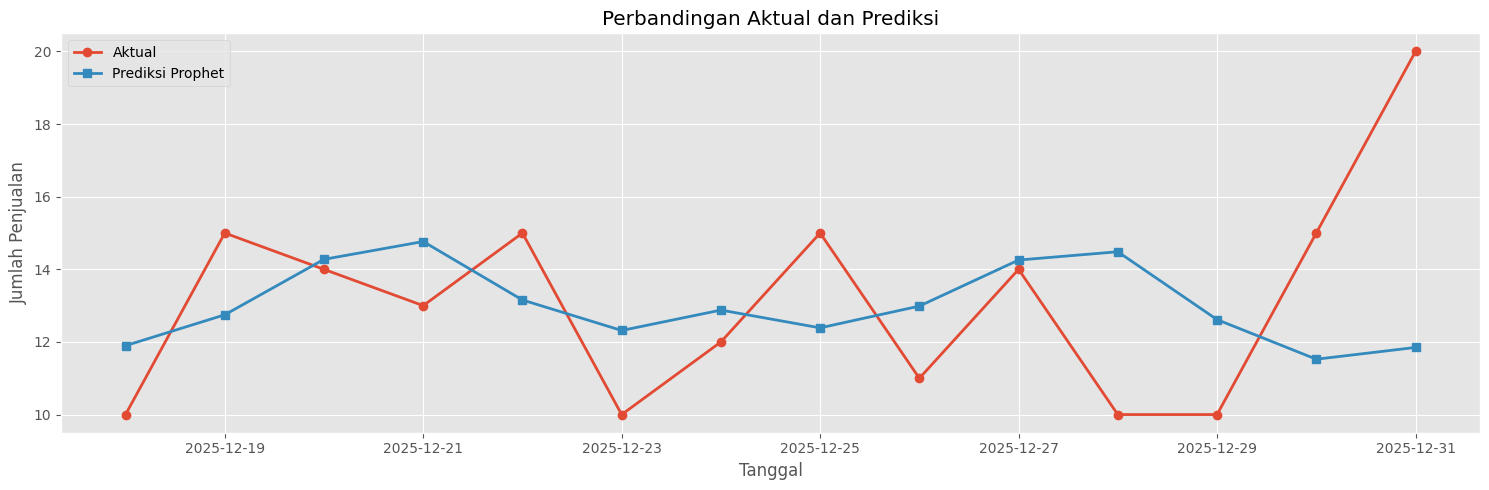

In [ ]:
# ============================================================
# GRAFIK AKTUAL VS PREDIKSI
# ============================================================

plt.figure(figsize=(15,5))

plt.plot(
    hasil["Tanggal"],
    hasil["Aktual"],
    marker="o",
    linewidth=2,
    label="Aktual"
)

plt.plot(
    hasil["Tanggal"],
    hasil["Prediksi"],
    marker="s",
    linewidth=2,
    label="Prediksi Prophet"
)

plt.legend()

plt.grid(True)

plt.xlabel("Tanggal")

plt.ylabel("Jumlah Penjualan")

plt.title("Perbandingan Aktual dan Prediksi")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "05_aktual_vs_prediksi.png"
    ),
    dpi=300
)

plt.show()

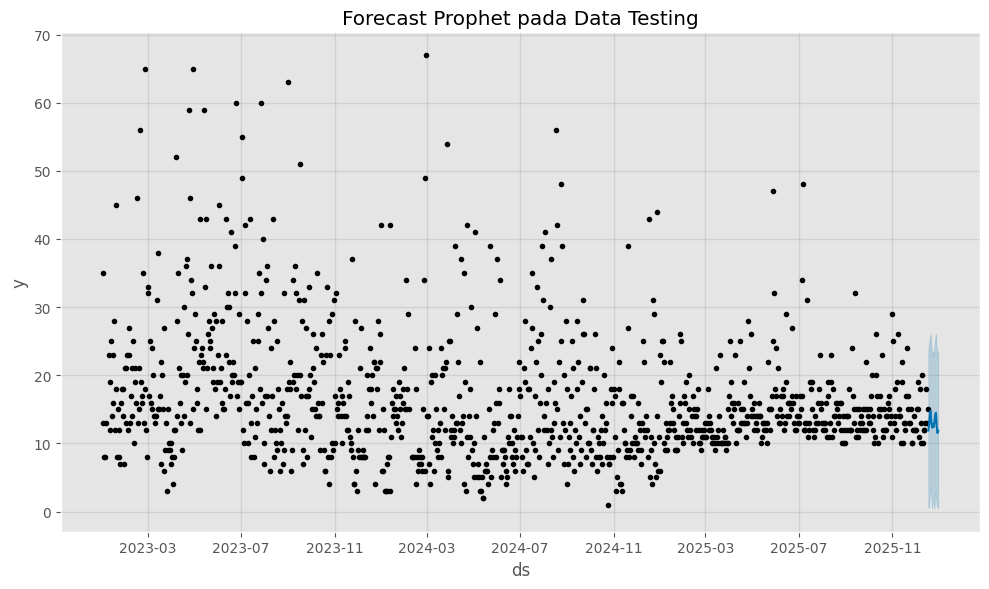

In [ ]:
# ============================================================
# GRAFIK FORECAST PROPHET
# ============================================================

fig = model.plot(forecast)

plt.title("Forecast Prophet pada Data Testing")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "06_forecast_testing.png"
    ),
    dpi=300
)

plt.show()

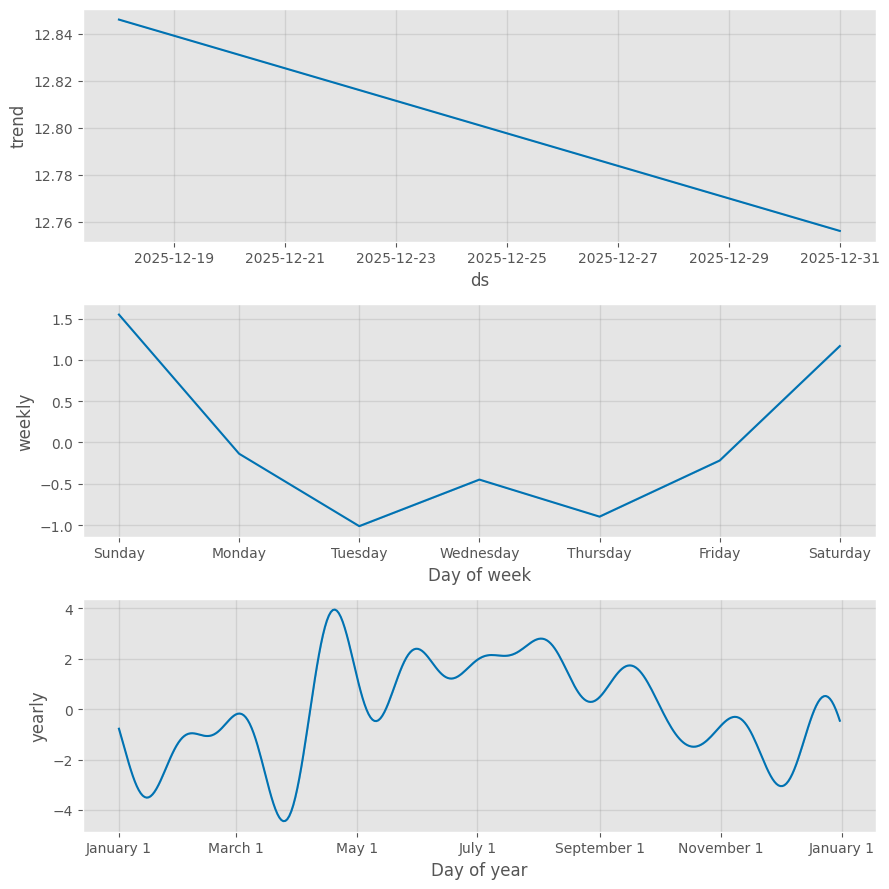

In [ ]:
# ============================================================
# GRAFIK KOMPONEN
# ============================================================

fig = model.plot_components(forecast)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "07_komponen_prophet.png"
    ),
    dpi=300
)

plt.show()

In [ ]:
# ============================================================
# MODEL FINAL
# ============================================================

model_final = Prophet(
    changepoint_prior_scale=CURRENT_SCALE,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model_final.fit(df)

00:47:05 - cmdstanpy - INFO - Chain [1] start processing
00:47:05 - cmdstanpy - INFO - Chain [1] done processing


In [ ]:
# ============================================================
# FORECAST 14 HARI
# ============================================================

future_final = model_final.make_future_dataframe(
    periods=LEAD_TIME
)

forecast_final = model_final.predict(
    future_final
)

forecast14 = forecast_final.tail(
    LEAD_TIME
)

display(

    forecast14[
        [
            "ds",
            "yhat",
            "yhat_lower",
            "yhat_upper"
        ]
    ]

)

,ds,yhat,yhat_lower,yhat_upper
1092,2026-01-01,11.301676,0.309882,23.367780
1093,2026-01-02,11.711862,0.452845,23.833744
1094,2026-01-03,12.812722,1.101949,23.867230
1095,2026-01-04,12.870968,0.827456,25.025802
1096,2026-01-05,10.943398,-0.257169,21.950644
1097,2026-01-06,9.803342,-1.857545,21.824595
1098,2026-01-07,10.139004,-0.717417,22.115682
1099,2026-01-08,9.400054,-1.743068,21.765138
1100,2026-01-09,9.847404,-1.710798,21.745820
1101,2026-01-10,11.020834,0.271476,22.608643


In [ ]:
# ============================================================
# SIMPAN FORECAST
# ============================================================

forecast_output = forecast14[
    [
        "ds",
        "yhat",
        "yhat_lower",
        "yhat_upper"
    ]
].copy()

forecast_output.columns = [
    "Tanggal",
    "Forecast",
    "Lower",
    "Upper"
]

forecast_output["Forecast"] = (
    forecast_output["Forecast"]
    .clip(lower=0)
    .round()
    .astype(int)
)

display(forecast_output)

forecast_output.to_excel(
    os.path.join(
        OUTPUT_FOLDER,
        "08_forecast_14_hari.xlsx"
    ),
    index=False
)

,Tanggal,Forecast,Lower,Upper
1092,2026-01-01,11,0.309882,23.367780
1093,2026-01-02,12,0.452845,23.833744
1094,2026-01-03,13,1.101949,23.867230
1095,2026-01-04,13,0.827456,25.025802
1096,2026-01-05,11,-0.257169,21.950644
1097,2026-01-06,10,-1.857545,21.824595
1098,2026-01-07,10,-0.717417,22.115682
1099,2026-01-08,9,-1.743068,21.765138
1100,2026-01-09,10,-1.710798,21.745820
1101,2026-01-10,11,0.271476,22.608643


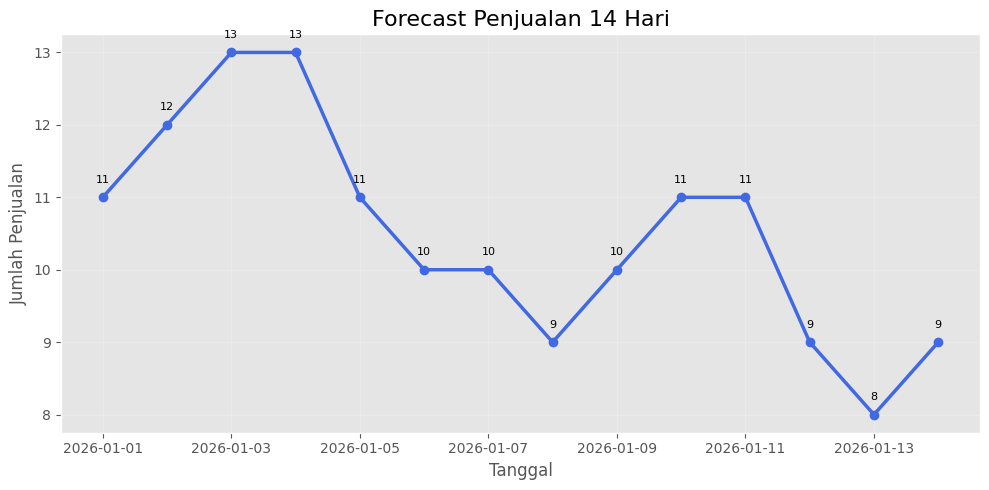

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    forecast_output["Tanggal"],
    forecast_output["Forecast"],
    marker='o',
    linewidth=2.5,
    color='royalblue'
)

for i, y in enumerate(forecast_output["Forecast"]):
    plt.text(
        forecast_output["Tanggal"].iloc[i],
        y + 0.2,
        str(y),
        fontsize=8,
        ha='center'
    )

plt.title("Forecast Penjualan 14 Hari", fontsize=16)
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan")
plt.grid(alpha=0.2)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

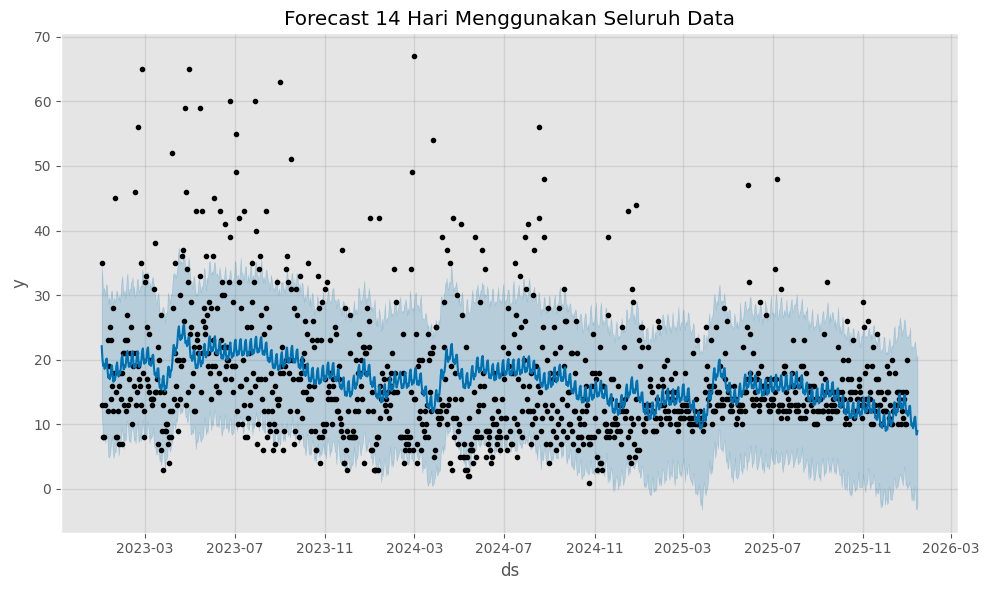

In [ ]:
# ============================================================
# GRAFIK FORECAST MASA DEPAN
# ============================================================

fig = model_final.plot(
    forecast_final
)

plt.title(
    "Forecast 14 Hari Menggunakan Seluruh Data"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "09_forecast_14hari.png"
    ),
    dpi=300
)

plt.show()

In [ ]:
# ============================================================
# RINGKASAN
# ============================================================

forecast_qty = int(
    forecast_output["Forecast"].sum()
)

print("="*60)
print("HASIL PENELITIAN")
print("="*60)
print("Produk :", SHEET)
print()
print("Forecast 14 Hari :", forecast_qty)
print()
print("MAE :", round(mae,2))
print("RMSE :", round(rmse,2))
print("MAPE :", round(mape,2),"%")
print("="*60)

HASIL PENELITIAN
Produk : aqua_600ml

Forecast 14 Hari : 147

MAE : 2.49
RMSE : 3.14
MAPE : 18.9 %


In [ ]:
# ============================================================
# INPUT DATA INVENTORY
# ============================================================

CURRENT_STOCK = 151      # isi sesuai stok saat ini
MOQ = 24                # isi sesuai supplier
LEAD_TIME = 14

print("="*60)
print("DATA INVENTORY")
print("="*60)

print("Current Stock :", CURRENT_STOCK)
print("MOQ           :", MOQ)
print("Lead Time     :", LEAD_TIME)

DATA INVENTORY
Current Stock : 151
MOQ           : 24
Lead Time     : 14


In [ ]:
# ============================================================
# FORECAST 14 HARI
# ============================================================

forecast_qty = int(
    round(
        forecast_output["Forecast"].sum()
    )
)

print()
print("Forecast 14 Hari :", forecast_qty)


Forecast 14 Hari : 147


In [ ]:
# ============================================================
# SAFETY STOCK
# ============================================================

safety_stock = int(
    round(mae * LEAD_TIME)
)

print()
print("Safety Stock :", safety_stock)


Safety Stock : 35


In [ ]:
# ============================================================
# REORDER POINT
# ============================================================

daily_demand = forecast_qty / LEAD_TIME
rop = int(
    round((daily_demand * LEAD_TIME) + safety_stock)
)

print()
print("Daily Demand :", round(daily_demand,2))
print("ROP :", rop)


Daily Demand : 10.5
ROP : 182


In [ ]:
# ============================================================
# REKOMENDASI PEMBELIAN
# ============================================================

recommendation = max(
    0,
    rop - CURRENT_STOCK
)

# ============================================
# PENYESUAIAN MOQ
# MOQ = BATAS MINIMUM PEMBELIAN
# BUKAN KELIPATAN PEMBELIAN
# ============================================

if recommendation > 0 and recommendation < moq:
    recommendation = moq

print()
print("Recommendation :", recommendation)


Recommendation : 48


In [ ]:
# ============================================================
# HASIL INVENTORY
# ============================================================

inventory = pd.DataFrame({
    "Forecast Qty":[forecast_qty],
    "Current Stock":[CURRENT_STOCK],
    "Lead Time":[LEAD_TIME],
    "MAE":[round(mae,2)],
    "Safety Stock":[safety_stock],
    "Daily Demand":[round(daily_demand,2)],
    "ROP":[rop],
    "MOQ":[MOQ],
    "Recommendation":[recommendation]
})

display(inventory)

inventory.to_excel(
    os.path.join(
        OUTPUT_FOLDER,
        "09_inventory.xlsx"
    ),
    index=False
)

,Forecast Qty,Current Stock,Lead Time,MAE,Safety Stock,Daily Demand,ROP,MOQ,Recommendation
0,147,151,14,2.49,35,10.5,182,24,48


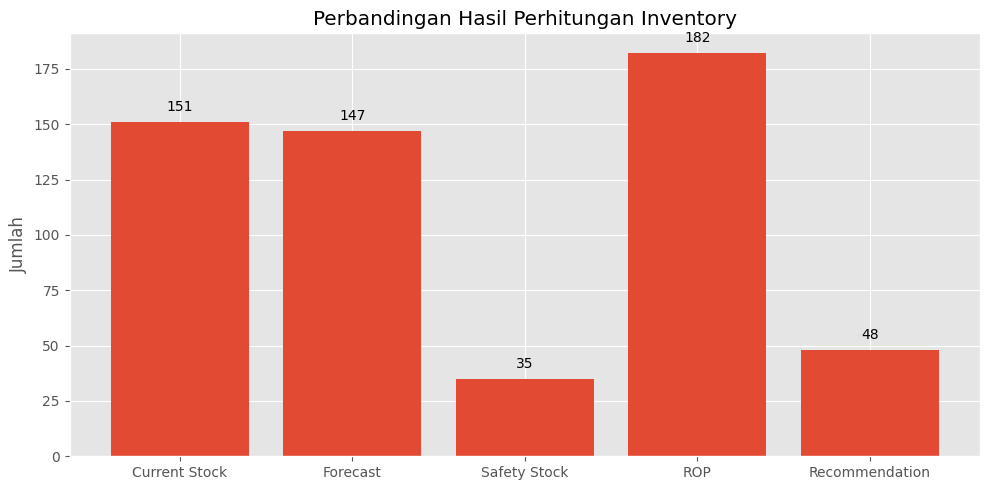

In [ ]:
# ============================================================
# VISUALISASI INVENTORY
# ============================================================

plt.figure(figsize=(10,5))

kategori = [
    "Current Stock",
    "Forecast",
    "Safety Stock",
    "ROP",
    "Recommendation"
]

nilai = [
    CURRENT_STOCK,
    forecast_qty,
    safety_stock,
    rop,
    recommendation

]

plt.bar(kategori, nilai)
plt.title("Perbandingan Hasil Perhitungan Inventory")

plt.ylabel("Jumlah")

for i,v in enumerate(nilai):
    plt.text(i, v+5, str(v), ha="center")

plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "10_inventory.png"
    ),
    dpi=300
)

plt.show()

In [ ]:
# ============================================================
# RINGKASAN HASIL PENELITIAN
# ============================================================

print("="*70)
print("SELURUH HASIL PENELITIAN BERHASIL DIBUAT")
print("="*70)
print()
print("Folder Output :")
print(OUTPUT_FOLDER)
print()
print("File yang dihasilkan :")
print()
for file in sorted(
    os.listdir(
        OUTPUT_FOLDER
    )
):
    print(file)
print()
print("="*70)

SELURUH HASIL PENELITIAN BERHASIL DIBUAT

Folder Output :
d:\SKRIPSI\POS\PROPHET\hasil_penelitian

File yang dihasilkan :

01_data_historis.png
02_training_testing.png
03_aktual_vs_prediksi.xlsx
03_training_testing_zoom.png
05_aktual_vs_prediksi.png
06_forecast_testing.png
07_komponen_prophet.png
08_forecast_14_hari.xlsx
09_forecast_14hari.png
09_inventory.xlsx
10_inventory.png

